In [10]:
from anemone.forwards import ForwardMatrix, ForwardLaplace6
import torch
from numpy import ndarray
import matplotlib.pyplot as plt
import numpy as np

In [11]:
rho = torch.tensor([20, 80, 40])
thick = torch.tensor([20, 30])

In [12]:
from anemone.experiment import Loop, Receiver, Waveform

t = torch.logspace(-5, -3, 40)
tx = Loop.square(40)
rx = Receiver()
waveform = Waveform.example()


In [13]:
fwr0 = ForwardLaplace6(tx, rx, t, waveform)
fwr1 = ForwardMatrix(tx, rx, t, waveform)
dbdt = fwr1(rho,thick)
G1 = fwr1(rho, thick, jac=True)

/home/matt/repositories/anemone/src/anemone/experiment/experiment.py:129: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return torch.tensor(overall_min)


In [14]:
fwr1 = ForwardMatrix(tx, rx, t, waveform)

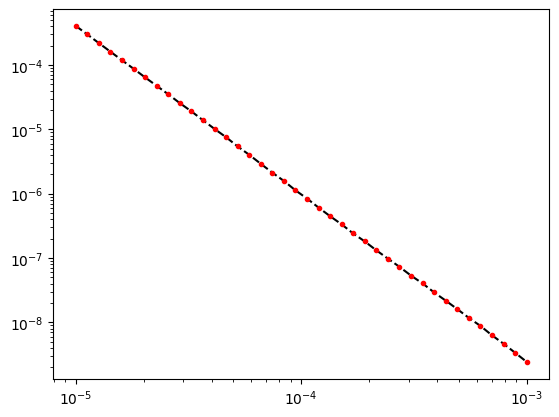

In [15]:
rho = torch.ones(31, dtype=torch.double)*40.
rho[5:10] = 20.
rho[25:27] = 90.

thick = torch.logspace(-1, 1.2, len(rho)-1, dtype=torch.double)
dbdt0 = fwr0(rho, thick)
dbdt1 = fwr1(rho, thick)

plt.figure()
plt.loglog(fwr0.times, dbdt0, 'k--')
plt.loglog(fwr1.times, dbdt1, 'r.')

In [16]:
# %%timeit
# dbdt1 = fwr1(rho, thick)

In [17]:
# %%timeit
dm = rho*0.02
rho_mat = rho[:, None] + torch.eye(len(rho))*dm
#if 'dbdt_mat' not in locals():
dbdt_mat = fwr0(rho_mat, thick)
G0 = (dbdt_mat - dbdt0[None, :]) / dm[:, None]
# G0 = G0.numpy()

In [18]:
fwr1 = ForwardMatrix(tx, rx, t, waveform)
dbdt = fwr1(rho, thick)
G1 = fwr1(rho, thick, jac=True)

In [28]:
from dolphinv import Tikhonov
from anemone.inversion import *

times = torch.logspace(-5,-2, 32)

In [29]:
def compute_relstd(t_gates, dbdt, noise_slope_exponent=-0.5, noise_level_at_1ms=1e-8, current=1., relative_noise=0.03):
    b = noise_level_at_1ms/(1e-3**noise_slope_exponent)
    abs_noise = b*(t_gates**noise_slope_exponent)
    y = dbdt*current
    std_rel = abs_noise/y
    relstd_tot = torch.sqrt(std_rel**2 + relative_noise**2)
    return relstd_tot

In [30]:
def logify_forward(cls):
    class LogFwr(cls):
        def __call__(self, *args, **kwargs):
            if not kwargs.get('jac', False):
                return super().__call__(*args, **kwargs).log10()
            else:
                return super().__call__(*args, **kwargs)
    return LogFwr

LFL6 = logify_forward(ForwardMatrix)

In [31]:
fwr1 = LFL6(tx, rx, times, waveform=waveform)

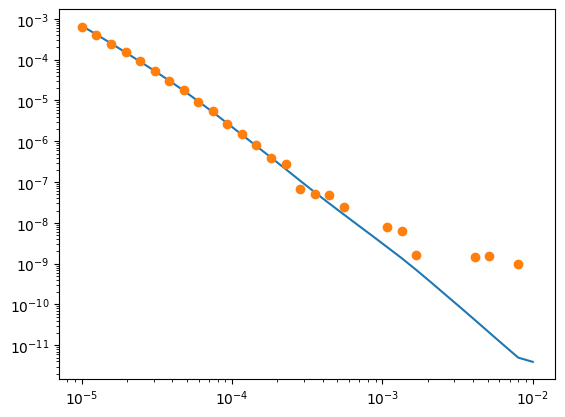

In [32]:
rho = torch.tensor([20, 100, 40])
thk = torch.tensor([30,40.])
mod_true = LogResistivity.few_layers(rho, thk)


dbdt_true = 10**fwr1(rho, thk)
d_relerr = compute_relstd(fwr1.times, dbdt_true, current=1.)
d_err = torch.log10(1. + d_relerr)

d_obs = dbdt_true + dbdt_true * torch.randn_like(dbdt_true) * d_relerr
#d_err = dbdt_true*d_relerr

plt.figure()
plt.loglog(fwr1.times, dbdt_true, '-', label='Observed')
plt.loglog(fwr1.times, d_obs, 'o', label='Observed')

d_obs = torch.abs(d_obs).log10()

In [33]:
class TikhoJacobian(Tikhonov):
    def jacobian(self, mvec):
        rho,thick = self.model.modelize(mvec)
        G = self.forward(rho, thick, jac=True)
        G *= rho[:,None]
        G /= 10**self.data_predicted
        return G.T

001	misfit:	2.41
002	misfit:	2.07
003	misfit:	1.81
004	misfit:	1.60
005	misfit:	1.43
006	misfit:	1.29
007	misfit:	1.20
008	misfit:	1.14
009	misfit:	1.10
010	misfit:	1.07
reached iteration cap..


[<Axes: title={'center': 'resistivity'}, ylabel='depth [m]'>]

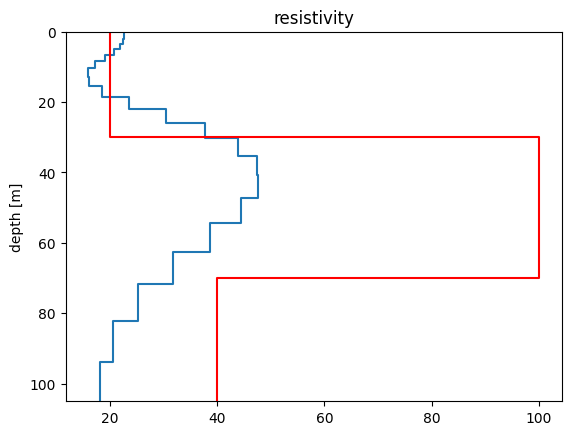

In [34]:
fwr1 = LFL6(tx, rx, times, waveform=waveform)

res_start = LogResistivity.smooth(torch.ones(30, dtype=torch.double)*20., torch.cumsum(torch.logspace(0,1.5,29), 0))
inv = TikhoJacobian(d_obs, d_err, res_start, fwr1)
inv.vertical_smoothness = 1e-2

res_mod = inv.invert(iter_cap=10)
ax = res_mod.plot()
mod_true.plot(axs=ax, color='red', label='True model')